# AEROLIFE · Pronóstico de vida remanente del turbofán
**Universidad Don Bosco · DAS172 · Proyecto integrador**  
NASA C-MAPSS FD001 · Semilla 42

El experimento abarca la ingesta y depuración de datos, el cálculo de características causales, la selección del modelo por motor, la calibración del intervalo y la evaluación oficial.

**Integrantes** · Adriana Zaira Salazar Guzmán, Marcela Lorena Martínez Linares, Andrea Alejandra Mejía Martínez, Diego Josué Hernández Martínez, Mauro José Abarca Gómez, Jaime Fernando Portillo Linares y Emma Leticia Zelada Salamanca.


## 1. Entorno y rutas relativas
El entorno de referencia usa Python 3.12 y las dependencias de `requirements-lock.txt`. El cuaderno admite ejecución desde la raíz del repositorio o desde `notebooks/`. Los archivos originales de FD001 incluyen su registro de procedencia y hashes SHA-256.


In [1]:
from pathlib import Path
import os, sys, json
if not Path('config.json').exists() and Path('../config.json').exists():
    os.chdir('..')
assert Path('config.json').exists(), 'Abra el notebook dentro del repositorio.'
sys.path.insert(0, str(Path('src')))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from rul.config import Config
from rul.data import download_data, read_raw, validate_and_clean
cfg = Config.load()
print('Configuración predefinida:', cfg.to_dict())
print(Path('requirements.txt').read_text())

Configuración predefinida: {'seed': 42, 'rul_cap': 125, 'calibration_engines': 20, 'cv_folds': 5, 'windows': (5, 15, 30), 'alpha': 0.1, 'n_jobs': 2, 'bootstrap_repetitions': 2000, 'min_history': 30}
# Tested with CPython 3.12.14. Install from the repository root.
pandas==3.1.1
numpy==2.5.4
scikit-learn==1.8.0
xgboost==3.4.1
matplotlib==3.10.8
seaborn==0.13.2
plotly==7.1.0
streamlit==1.66.1
scipy==1.18.1
nbformat==5.11.1
nbclient==0.11.0
ipykernel==7.4.0
reportlab==4.4.9
PyMuPDF==1.26.6
Pillow==13.0.0
pytest==9.2.0
joblib==1.5.3
ipython==9.18.1
jupyter-client==8.10.0



## 2. Fuente y consistencia
ID, ciclo, tres ajustes y 21 sensores. Temperaturas absolutas: Rankine a kelvin; presiones: psia a kPa absoluto. Los canales ambiguos conservan unidades nativas. Los extremos estadísticos se señalan sin borrar degradación; los imposibles físicos pasan a faltantes y se imputan con mediana de entrenamiento, dentro de cada fold.

In [2]:
provenance = download_data()
print(json.dumps(provenance, indent=2))
train_raw, audit = validate_and_clean(read_raw('data/raw/train_FD001.txt'))
display(pd.DataFrame([audit]))
display(train_raw.head())

{
  "source_page": "https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/",
  "download_url": "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip",
  "citation": "A. Saxena and K. Goebel (2008). Turbofan Engine Degradation Simulation Data Set. NASA Ames PCoE.",
  "sha256": {
    "train_FD001.txt": "963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8",
    "test_FD001.txt": "3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851",
    "RUL_FD001.txt": "a19c8ec94931949d0485bdc35118206e9c81c4547b422efb9cf86f4ceddbceca"
  }
}


,rows,engines,duplicate_keys,input_missing_cells,nonfinite_cells,nonpositive_sensor_cells,missing_after_physics,rows_removed,cycle_gaps
0,20631,100,0,0,0,0,0,0,0


,engine_id,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044


## 3. Experimento completo sin fuga
20 motores reservados para calibrar; 80 para selección con GroupKFold de cinco folds. Imputador, selector de varianza y escalador se ajustan en el fold de entrenamiento exclusivamente. Ocho candidatos de cuatro familias se comparan con RMSE sobre **un punto pseudo-censurado por motor**, uniforme entre ciclos >=30 anteriores al fallo (semilla 43). Los objetivos de ajuste se limitan a 125; CV y prueba usan verdad completa. Peso total igual por motor.

La celda siguiente reentrena todo y reemplaza los resultados derivados. Puede tardar varios minutos. La repetición reproduce el protocolo fijado; no permite ajustar parámetros a la prueba oficial.

In [3]:
from rul.pipeline import run_pipeline
metrics = run_pipeline(cfg)
display(pd.read_csv('reports/model_comparison.csv'))
print(json.dumps(metrics['official_test'], indent=2))

CV fold 1/5 completo
CV fold 2/5 completo
CV fold 3/5 completo
CV fold 4/5 completo
CV fold 5/5 completo
Modelo seleccionado por CV: RandomForest_leaf3
{
  "selected": "RandomForest_leaf3",
  "official_test": {
    "rmse": 17.186491211461938,
    "mae": 12.327624914861488,
    "r2": 0.8289532225469378,
    "bias": -0.4977995023836874,
    "nasa_score": 491.7273338976054,
    "n": 100,
    "rmse_ci95_engine_bootstrap": [
      14.349367490337903,
      19.803221910483906
    ],
    "interval_coverage90": 1.0,
    "mean_interval_width": 172.75541922117117,
    "conformal_radius": 101.73738809834374
  }
}


,candidate,cv_rmse,cv_sd,cv_mae
0,RandomForest_leaf3,31.835538,10.035262,21.783121
1,RandomForest_leaf8,32.202539,9.844533,21.971468
2,XGBoost_d4_n700,32.358487,10.564769,21.793126
3,XGBoost_d4_n450,32.599587,10.539176,22.051289
4,XGBoost_d3_n450,32.687679,10.291860,22.502867
5,Ridge_a10,34.192814,9.399724,24.316008
6,Ridge_a100,34.389370,9.337334,24.588849
7,Median_baseline,54.026673,9.089392,42.450000


{
  "rmse": 17.186491211461938,
  "mae": 12.327624914861488,
  "r2": 0.8289532225469378,
  "bias": -0.4977995023836874,
  "nasa_score": 491.7273338976054,
  "n": 100,
  "rmse_ci95_engine_bootstrap": [
    14.349367490337903,
    19.803221910483906
  ],
  "interval_coverage90": 1.0,
  "mean_interval_width": 172.75541922117117,
  "conformal_radius": 101.73738809834374
}


## 4. EDA e inferencia por motor
H0 bilateral: mediana de la diferencia entre media tardía (últimos 30 ciclos) y temprana (primeros 30) = 0. Wilcoxon pareado bajo simetría de diferencias, Holm para ocho contrastes y bootstrap de 2 000 motores. No se trata cada ciclo como observación independiente. El heatmap es descriptivo; una asociación no identifica una avería real ni demuestra causalidad.

,sensor,symbol,n_engines,mean_late_minus_early,median_difference,mean_ci95_lower,mean_ci95_upper,wilcoxon_W,p_raw,rank_biserial,p_holm
0,s2,T24,80,0.558164,0.547685,0.533229,0.583610,0.0,7.849527e-15,1.0,6.278514e-14
1,s3,T30,80,6.641009,6.707778,6.350011,6.946738,0.0,7.849527e-15,1.0,6.278514e-14
2,s4,T50,80,11.251023,11.360093,10.781947,11.697375,0.0,7.849527e-15,1.0,6.278514e-14
3,s7,P30,80,-13.310588,-13.124171,-13.959495,-12.595893,0.0,7.849527e-15,-1.0,6.278514e-14
4,s11,Ps30,80,4.256565,4.132258,4.056352,4.455223,0.0,7.848142e-15,1.0,6.278514e-14
5,s12,phi,80,-0.107305,-0.106489,-0.112881,-0.101510,0.0,7.849527e-15,-1.0,6.278514e-14
6,s20,W31,80,-0.171934,-0.167224,-0.179218,-0.164213,0.0,7.848834e-15,-1.0,6.278514e-14
7,s21,W32,80,-0.103503,-0.100171,-0.107867,-0.099284,0.0,7.849527e-15,-1.0,6.278514e-14


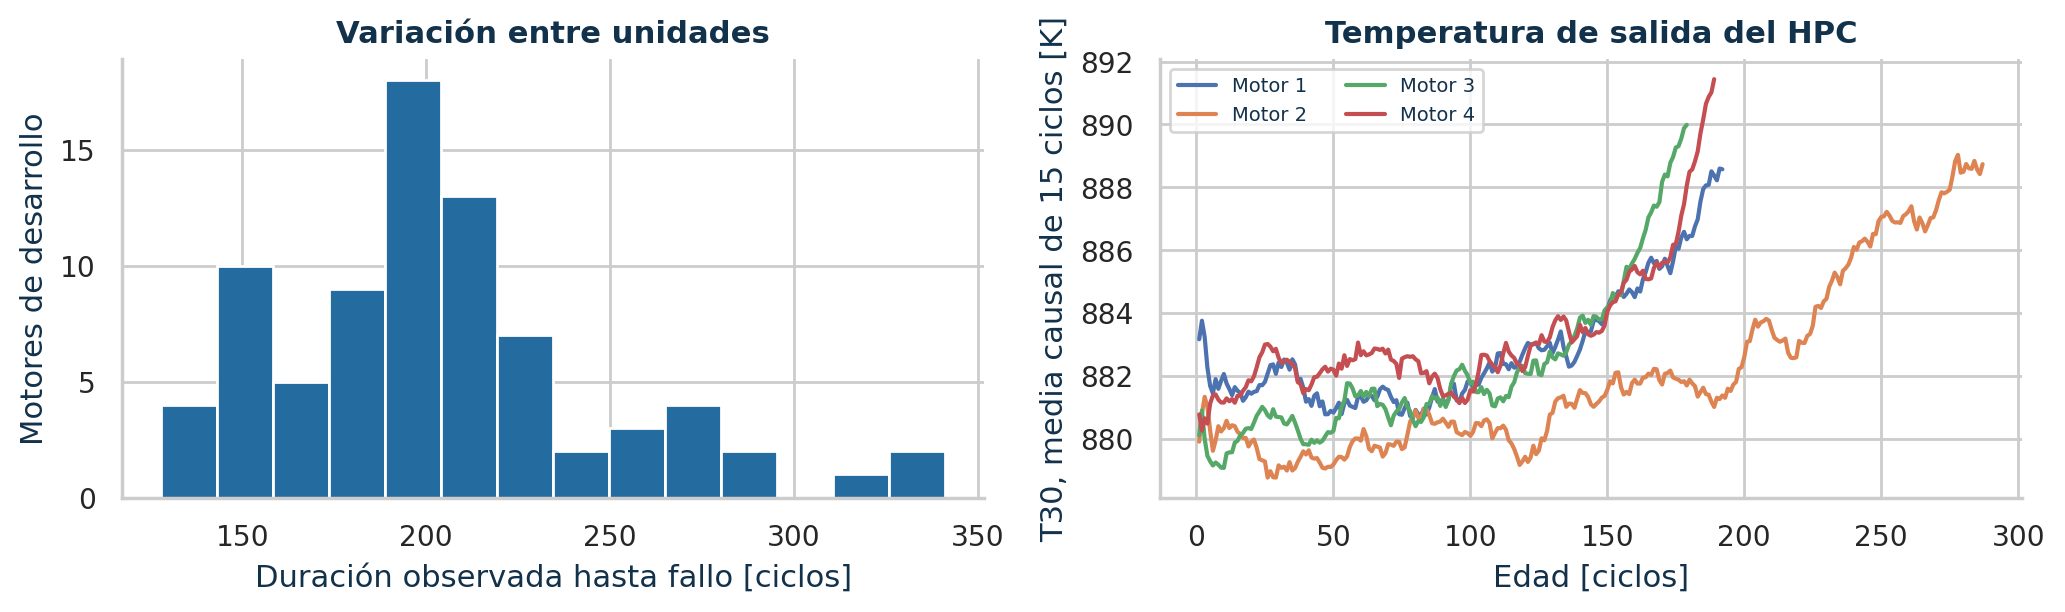

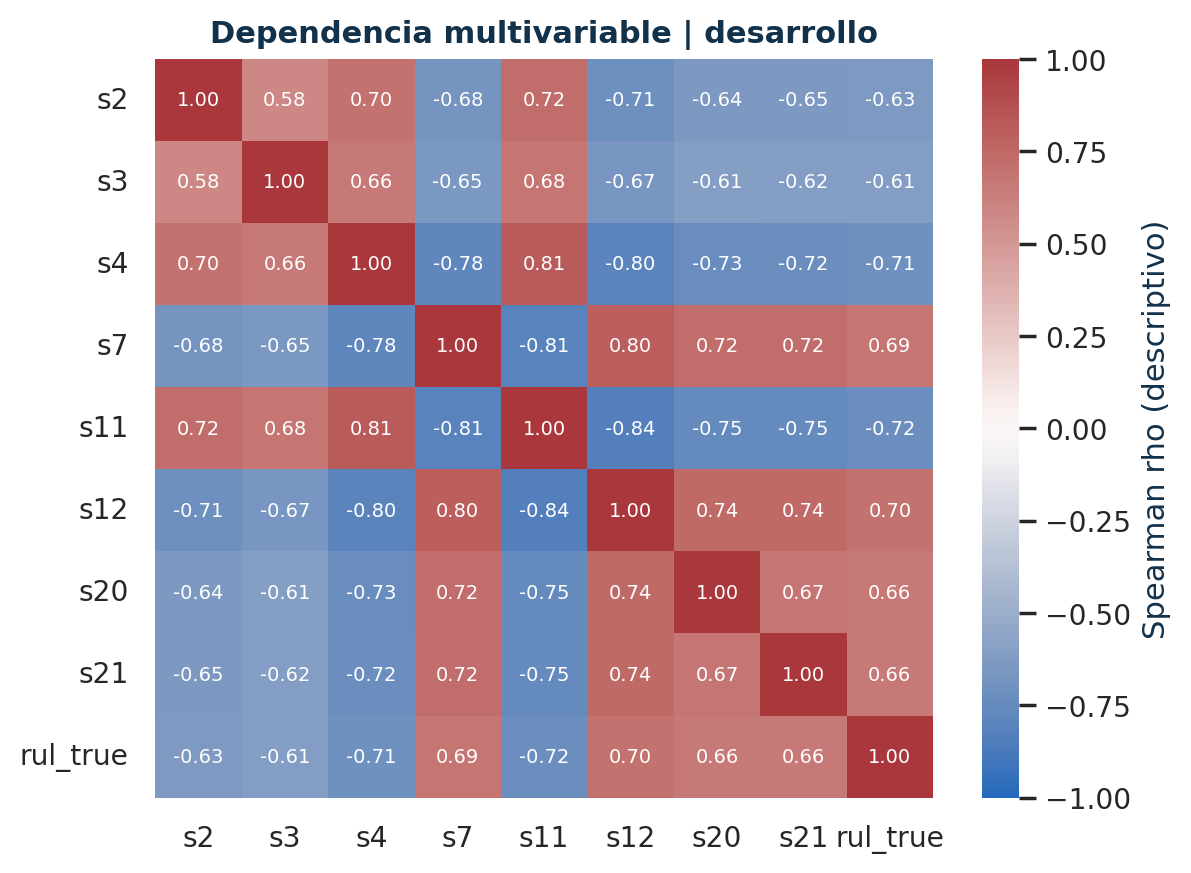

In [4]:
display(pd.read_csv('reports/hypothesis_tests.csv'))
display(Image(filename='reports/figures/eda_lifetime_trajectories.png'))
display(Image(filename='reports/figures/eda_correlation.png'))

## 5. Selección, residuos e incertidumbre
El predictor final se ajusta solo en 80 motores. Los 20 errores de calibración absolutos determinan el radio conformal de orden `ceil(21*0.9)=19`. Se serializa el modelo antes de abrir las etiquetas oficiales, sin reajustarlo con calibración.

La cobertura nominal 90% exige intercambio entre unidades calibradas y futuras; los protocolos de censura pueden diferir. Se reporta cobertura observada sin prometer cobertura condicional por motor ni simultánea por trayectoria. El RMSE oficial no recorta la verdad NASA; el RMSE con verdad limitada se reporta solo como secundario.

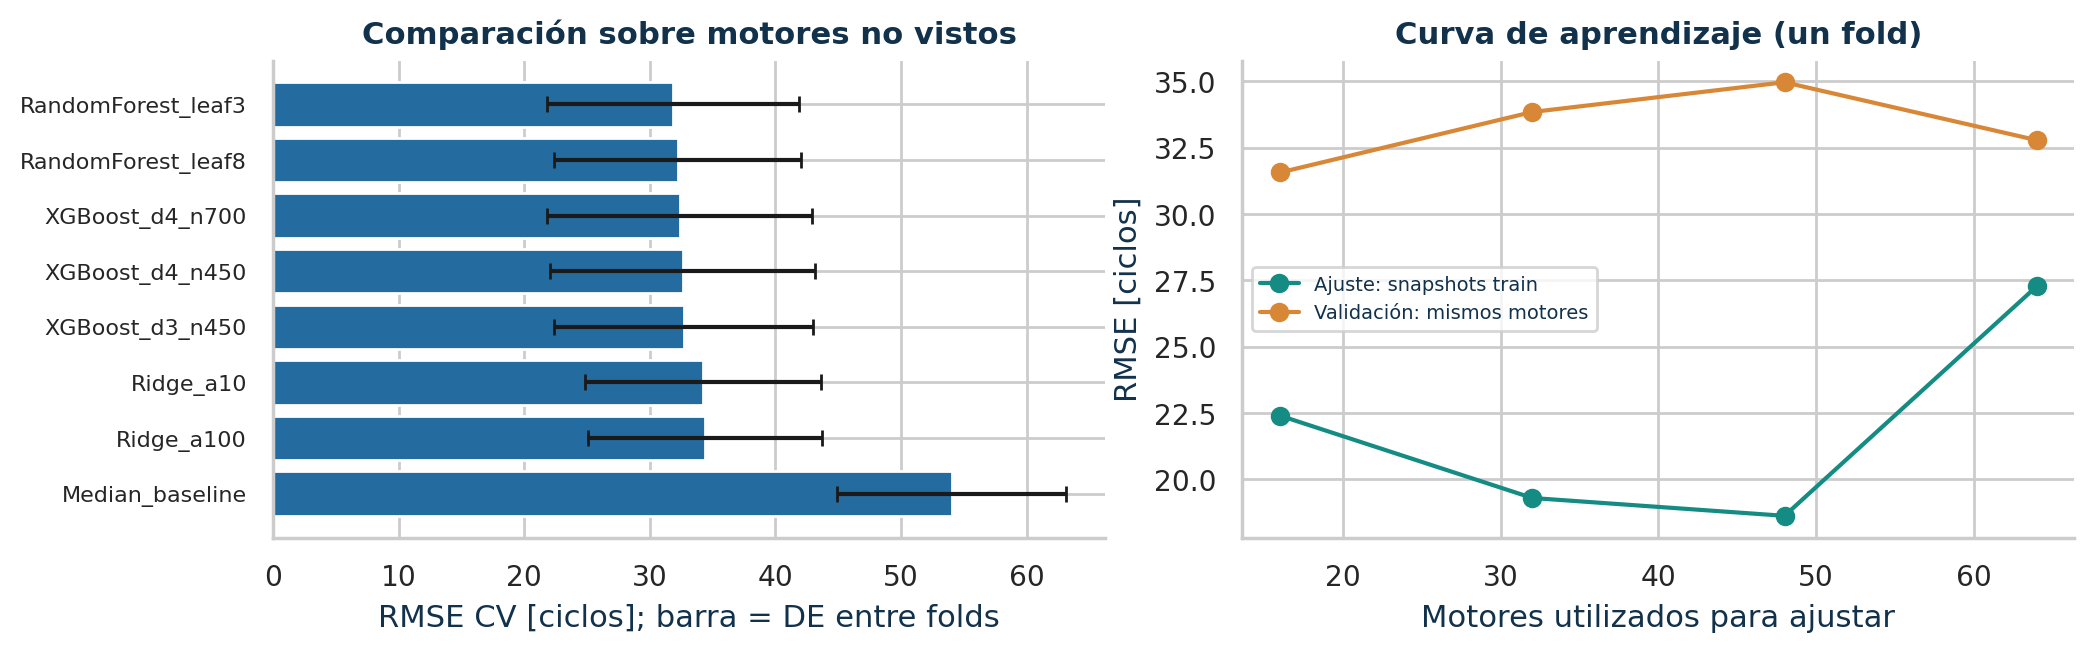

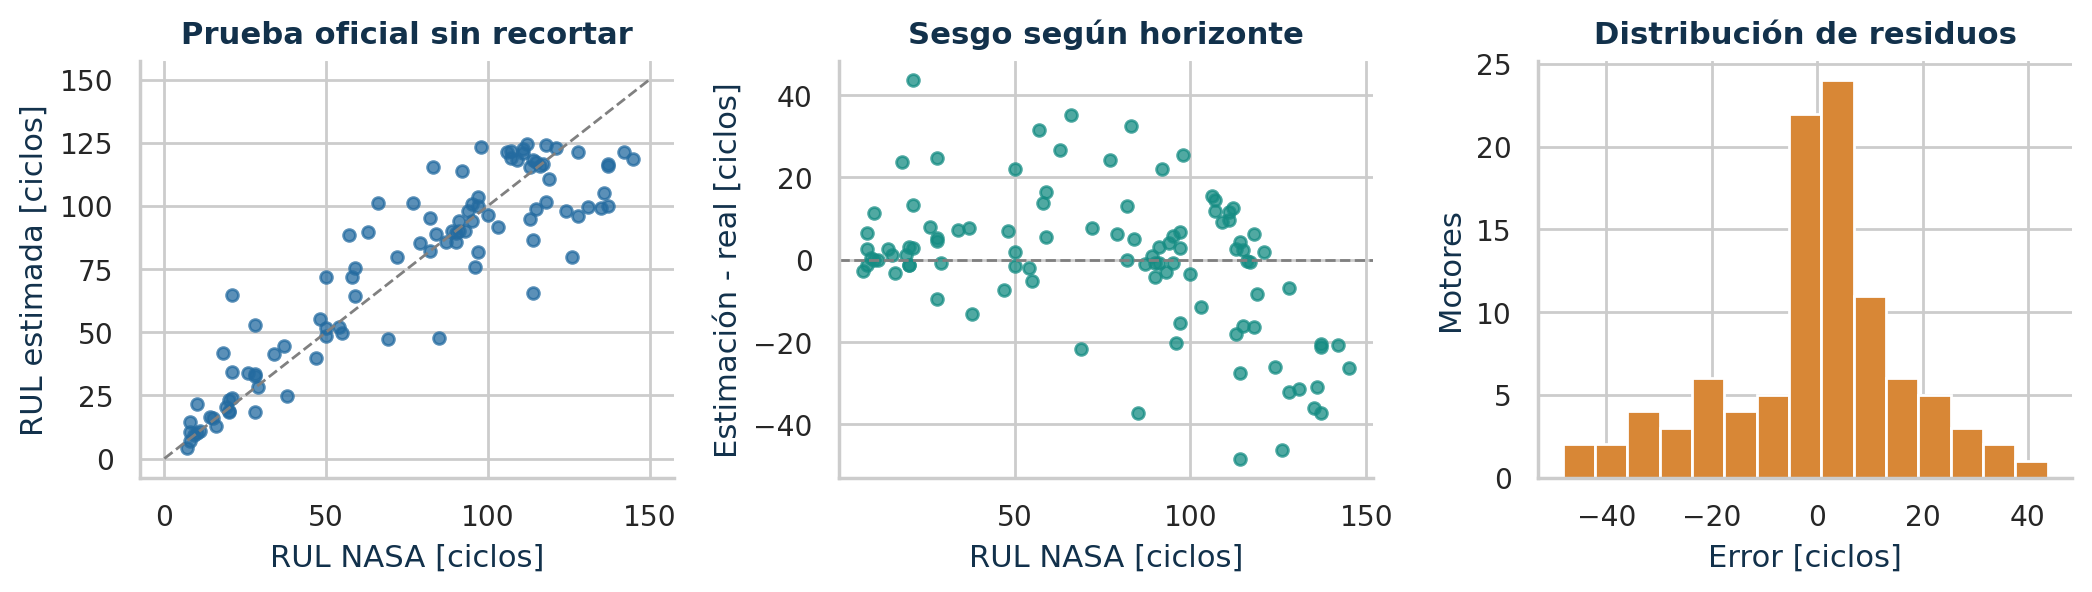

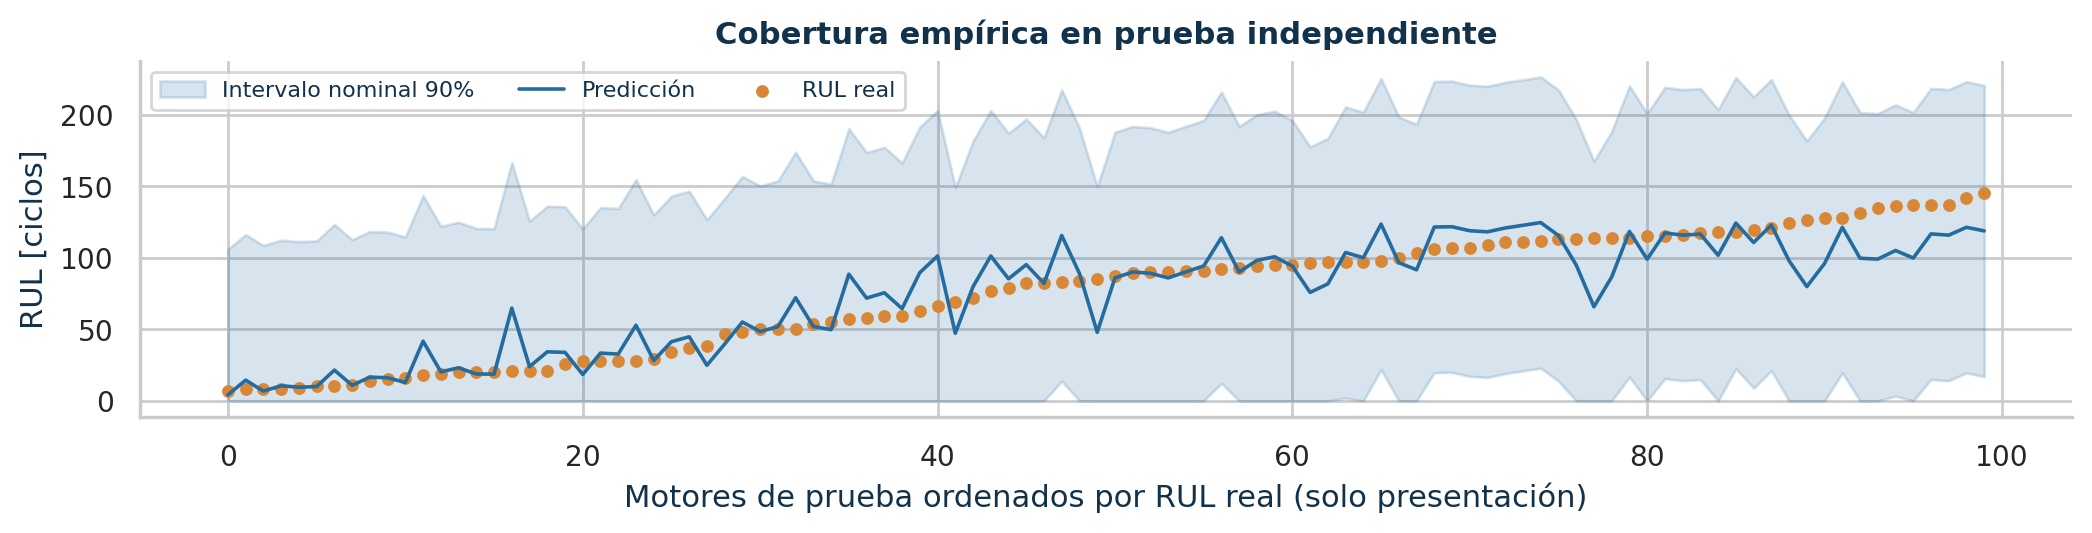

,horizon,rmse,mae,r2,bias,nasa_score,n
0,RUL<=30,12.163447,7.018247,-1.778832,5.378757,111.034686,25
1,30<RUL<=80,16.572725,13.212552,-0.834827,8.086333,107.455005,20
2,RUL>80,19.233355,14.419187,-0.257240,-6.290464,273.237643,55


,rmse,mae,r2,bias,nasa_score,n,nota
0,15.868026,11.257625,0.843204,0.5722,441.391988,100,Secundaria: verdad limitada a 125


In [5]:
display(Image(filename='reports/figures/model_selection.png'))
display(Image(filename='reports/figures/test_residuals.png'))
display(Image(filename='reports/figures/test_intervals.png'))
display(pd.read_csv('reports/metrics_by_horizon.csv'))
display(pd.DataFrame([metrics['secondary_capped_target']]).assign(nota='Secundaria: verdad limitada a 125'))

## 6. Decisiones de ingeniería
L = límite inferior. Revisión prioritaria si L<=10; planificación si 10<L<=40; seguimiento si L>40. Reevaluar como máximo en `floor(min(20,max(0,L-10)))` ciclos. Son supuestos configurables de demostración, no intervalos del fabricante. La sensibilidad usa costo ilustrativo `FP+20*FN`, sin dólares ni efecto causal demostrado sobre AOG.

,horizon,tp,fp,fn,tn,recall,precision,illustrative_cost_units
0,15,10,90,0,0,1.0,0.10,90
1,30,25,75,0,0,1.0,0.25,75
2,45,28,72,0,0,1.0,0.28,72


,engine_key,engine_id,last_cycle,rul_true,rul_pred,error,lower90,upper90,status,revisit_cycles
3,test:4,4,106,82.0,95.143989,13.143989,0.0,196.881378,Revisión prioritaria,0
2,test:3,3,126,69.0,47.210421,-21.789579,0.0,148.947809,Revisión prioritaria,0
5,test:6,6,105,93.0,90.012465,-2.987535,0.0,191.749853,Revisión prioritaria,0
4,test:5,5,98,91.0,90.088265,-0.911735,0.0,191.825653,Revisión prioritaria,0
6,test:7,7,160,91.0,94.208234,3.208234,0.0,195.945622,Revisión prioritaria,0
7,test:8,8,166,95.0,100.655234,5.655234,0.0,202.392622,Revisión prioritaria,0
10,test:11,11,83,97.0,81.676195,-15.323805,0.0,183.413583,Revisión prioritaria,0
9,test:10,10,192,96.0,75.749014,-20.250986,0.0,177.486403,Revisión prioritaria,0
15,test:16,16,113,84.0,88.937862,4.937862,0.0,190.675250,Revisión prioritaria,0
12,test:13,13,195,95.0,94.119105,-0.880895,0.0,195.856493,Revisión prioritaria,0


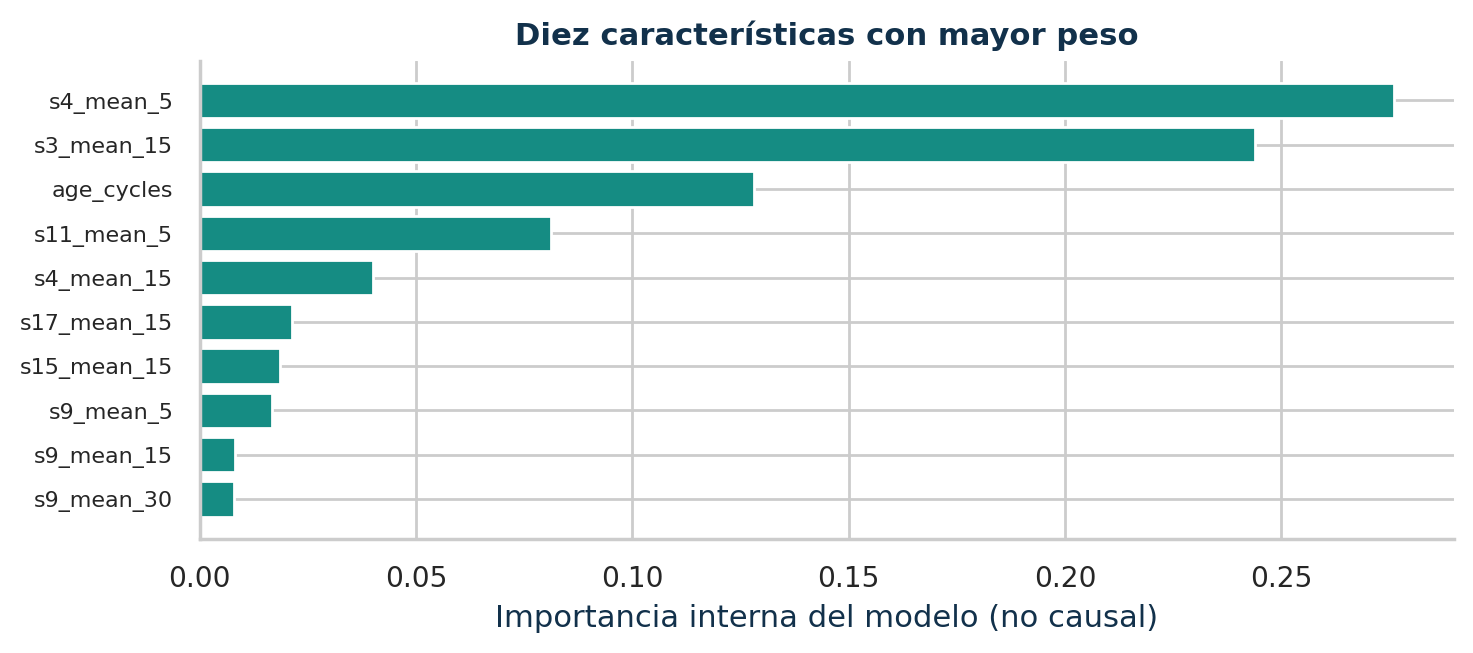

In [6]:
display(pd.read_csv('reports/policy_sensitivity.csv'))
pred = pd.read_csv('reports/test_predictions.csv')
display(pred.sort_values('lower90').head(12))
display(Image(filename='reports/figures/feature_importance.png'))

## 7. Separación e inferencia serializada
`train:1` y `test:1` son trayectorias diferentes aunque NASA reutilice el ID entero. La inferencia no consume etiquetas y solo transforma el historial pasado.

In [7]:
split = json.loads(Path('reports/split_manifest.json').read_text())
assert not set(split['development_ids']) & set(split['calibration_ids'])
for fold in split['folds']:
    assert not set(fold['fit_engine_ids']) & set(fold['validation_engine_ids'])
assert split['model_hash_unchanged_after_test']
from rul.inference import load_bundle, predict_history
example = read_raw('data/raw/test_FD001.txt').query('engine_id == 1')
replayed, _, _ = predict_history(example, load_bundle())
np.testing.assert_allclose(replayed.rul_pred.iloc[-1], pred.query('engine_id == 1').rul_pred.iloc[0], rtol=1e-6)
print('Separación, congelación e inferencia verificadas.')

Separación, congelación e inferencia verificadas.


## 8. Informe, panel y referencias

- [Informe técnico](../reports/Reporte_Tecnico_RUL_Turbofan.pdf)
- [Panel interactivo](../dashboard/Panel_Interactivo_AEROLIFE.zip)
- [Diccionario de datos](../reports/DICCIONARIO_DATOS.md)
- [Referencias](../reports/REFERENCIAS.md)
